### Multiplot for requested extended analysis

In [21]:
import pandas as pd
import plotnine as pn
import patchworklib as pw
print(pw.__version__)
print(pn.__version__)

0.5.0
0.8.0


In [22]:
eu_mdl_data = pd.read_csv(
    "../../multirun/universe=cognition/prior=modality_corpus/utility=half_credit/agent_type=literal/analysis/all_data.csv",
)

eu_hw_data = pd.read_csv(
    "../../multirun/universe=cognition/prior=modality_corpus/utility=half_credit/agent_type=literal_hw/analysis/all_data.csv",
)

eu_num_words_data = pd.read_csv(
    "../../multirun/universe=cognition/prior=modality_corpus/utility=half_credit/agent_type=literal_num_words/analysis/all_data.csv",
)

ib_mdl_data = pd.read_csv(
    "../../multirun/universe=cognition/prior=modality_corpus/utility=half_credit/agent_type=ib_mdl/analysis/all_data.csv",
)

ib_hw_data = pd.read_csv(
    "../../multirun/universe=cognition/prior=modality_corpus/utility=half_credit/agent_type=ib_hw/analysis/all_data.csv",
)

ib_num_words_data = pd.read_csv(
    "../../multirun/universe=cognition/prior=modality_corpus/utility=half_credit/agent_type=ib_num_words/analysis/all_data.csv",
)

## Generate multiplot

#### First inspect individual plots

In [23]:
def get_plot(
    input_data: pd.DataFrame, 
    complexity_measure: str, 
    comm_cost_measure: str,
):

    data = input_data.copy() # this helps

    pareto_data = data[data["dominant"] == True]
    natural_data = data[data["natural"] == True]

    og_data = data.copy()
    subset = [
        complexity_measure,
        comm_cost_measure,
    ]
    vcs = data.value_counts(subset=subset, sort=False)
    data = og_data.drop_duplicates(subset=subset)  # drop dupes from original
    data = data.sort_values(by=subset)
    data["counts"] = vcs.values

    # aesthetics for all data
    kwargs = {
        "color": "iff",
        "size": "counts",
    }

    plot = (
        # Set data and the axes
        pn.ggplot(mapping=pn.aes(x=complexity_measure, y=comm_cost_measure))
        # + pn.scale_y_continuous(limits=[0, 1])
        + pn.geom_point(data=pareto_data)
        + pn.geom_point(  # all langs
            data=data,
            stroke=0,
            alpha=1,
            mapping=pn.aes(**kwargs),
        )
        # + pn.xlab("Complexity")
        # + pn.ylab("Communicative cost")
        + pn.scale_color_cmap("cividis")
        + pn.theme_classic()
    )
    if natural_data is not None:
        plot = (
            plot
            + pn.geom_point(  # The natural languages
                natural_data,
                color="red",
                shape="+",
                size=4,
            )
            # + pn.geom_text(
            #     natural_data,
            #     pn.aes(label="name"),
            #     ha="left",
            #     size=6,  # orig 9
            #     nudge_x=1,
            # )
        )
    return plot

### Define individual subplots

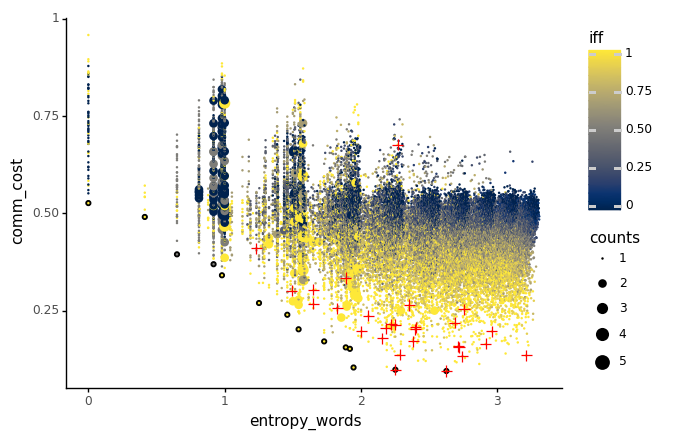

<ggplot: (394781477)>

In [24]:
get_plot(
    # eu_num_words_data,
    eu_hw_data,
    # "num_words_complexity",
    "entropy_words",
    # "complexity",
    "comm_cost",
)

#### Stitch together multiplot with patchworklib

In [25]:
# Grid: 
# top row = comm cost, bottom row = ib_comm_cost
# 1st col: mdl, h(w), |L|


# First: Upper left
# (main analysis)
ul_plot = (
    get_plot(
        eu_mdl_data,
        "complexity",
        "comm_cost",
    )
    + pn.theme(
                figure_size=(12, 9),
                legend_position='none',
                # legend_box='vertical',
                axis_title_x=pn.element_blank(),
                axis_title_y=pn.element_blank(),
                # plot_title=pn.element_text(margin={"t":0, "b":150, "l":0, "r":0}),
                # axis_title_y=pn.element_text(margin={"t":0, "b":0, "l":0, "r":20})
    )    
)

# Second: Upper center
uc_plot = (
    get_plot(
        eu_hw_data,
        "entropy_words",
        "comm_cost",
    )
    + pn.theme(
                figure_size=(12, 9),
                legend_position='none',
                # legend_box='vertical',
                axis_title_x=pn.element_blank(),
                axis_title_y=pn.element_blank(),
                # plot_title=pn.element_text(margin={"t":0, "b":200, "l":0, "r":20}),
        )
)

# Third: Upper right
ur_plot = (
    get_plot(
        eu_num_words_data,
        "num_words_complexity",
        "comm_cost",
    )
    + pn.theme(
                figure_size=(12, 9),
                # legend_position=(2., -1.),
                legend_position='none',
                legend_box='vertical',
                axis_title_x=pn.element_blank(),
                axis_title_y=pn.element_blank(),
                # plot_title=pn.element_text(margin={"t":0, "b":200, "l":20, "r":0}),
    )    


)


# Fourth: Lower left
ll_plot = (
    get_plot(
        ib_mdl_data,
        "complexity",
        "ib_comm_cost",
    )
    + pn.theme(
                figure_size=(12, 9),
                legend_position='none',
                # legend_box='vertical',
                axis_title_x=pn.element_blank(),
                axis_title_y=pn.element_blank(),
                # axis_title_y=pn.element_text(margin={"t":0, "b":0, "l":0, "r":20})
    ) 
)

# Fifth: Lower center
lc_plot = (
    get_plot(
        ib_hw_data,
        "entropy_words",
        "ib_comm_cost",
    )
    + pn.theme(
                figure_size=(12, 9),
                legend_position='none',
                # legend_box='vertical',
                axis_title_x=pn.element_blank(),
                axis_title_y=pn.element_blank(),
    )
)

# Sixth: Lower right
lr_plot = (
    get_plot(
        ib_num_words_data,
        "num_words_complexity",
        "ib_comm_cost",
    )
    + pn.theme(
                figure_size=(12, 9),
                legend_position='none',
                # legend_box='horizontal',
                # legend_title_align='center',
                axis_title_x=pn.element_blank(),
                axis_title_y=pn.element_blank(),
    )    
)

#### Stitch together multiplot with patchworklib

In [26]:
g_ul_plot = pw.load_ggplot(ul_plot, figsize=(2,2))
g_uc_plot = pw.load_ggplot(uc_plot, figsize=(2,2))
g_ur_plot = pw.load_ggplot(ur_plot, figsize=(2,2))

g_ll_plot = pw.load_ggplot(ll_plot, figsize=(2,2))
g_lc_plot = pw.load_ggplot(lc_plot, figsize=(2,2))
g_lr_plot = pw.load_ggplot(lr_plot, figsize=(2,2))

# Takes about 10s
g = (g_ul_plot | g_uc_plot | g_ur_plot) / (g_ll_plot | g_lc_plot | g_lr_plot)

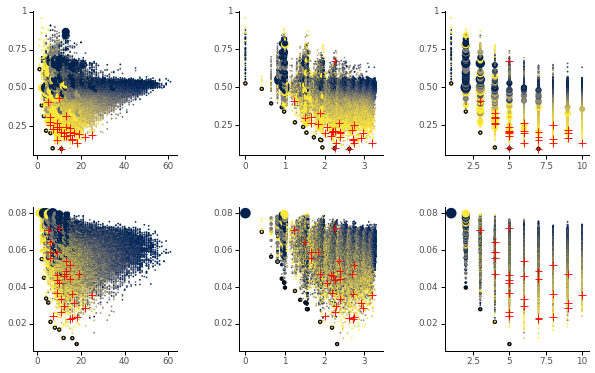

In [27]:
# Takes about 30s
g.savefig("multiplot_extended.pdf", dpi=300)

### Numerical analysis

MDL

In [28]:
import numpy as np
from scipy.stats import pearsonr

In [29]:
def iff_correlations(data: pd.DataFrame, properties: list[str]) -> dict[str, float]:
    prop_corrs = dict()
    for prop in properties:
        result = pearsonr(data.iff, data[prop])
        prop_corrs[prop] = result[0]
    return prop_corrs


In [30]:
iff_correlations(
    eu_mdl_data,
    [
        "simplicity",
        "informativity",
        "optimality",
    ]
)

{'simplicity': 0.48348587935986875,
 'informativity': 0.5776745129767695,
 'optimality': 0.557149749675554}

for 'simplicity', we'll just take the negative complexity correlation.

In [31]:
iff_correlations(
    eu_hw_data,
    [
        "entropy_words_simplicity",
        "informativity",
        "optimality",
    ]
)

{'entropy_words_simplicity': -0.007224398854570496,
 'informativity': 0.5675887270151591,
 'optimality': 0.48102396780543544}

In [32]:
iff_correlations(
    eu_num_words_data,
    [
        "num_words_simplicity",
        "informativity",
        "optimality",
    ]
)

{'num_words_simplicity': -0.06981038746027472,
 'informativity': 0.5675887270151591,
 'optimality': 0.33686160627660744}

In [45]:
iff_correlations(
    ib_mdl_data,
    [
        "simplicity",
        "ib_accuracy",
        "optimality",
    ]
)

{'simplicity': 0.48348587935987164,
 'ib_accuracy': 0.32718012019435655,
 'optimality': 0.38408454742820675}

In [43]:
iff_correlations(
    ib_hw_data,
    [
        "entropy_words_simplicity",
        "ib_accuracy",
        "optimality",
    ]
)

{'entropy_words_simplicity': -0.007224398854570496,
 'ib_accuracy': 0.32718012019435655,
 'optimality': 0.3218694403823427}

In [46]:
iff_correlations(
    ib_num_words_data,
    [
        "num_words_simplicity",
        "ib_accuracy",
        "optimality",
    ]
)

{'num_words_simplicity': -0.06981038746027472,
 'ib_accuracy': 0.32718012019435655,
 'optimality': 0.29461707712089397}

Population means

In [47]:
def pop_means(data: pd.DataFrame, properties: list[str]) -> dict[str, float]:
    prop_means = dict()
    data_subset = data[data.natural == True]

    for prop in properties:
        natural_mean = data_subset[prop].mean()
        pop_mean = data[prop].mean()
        result_dict = {
            "natural": natural_mean,
            "population": pop_mean,
            "nat - pop": natural_mean - pop_mean,
        }
        prop_means[prop] = result_dict
    
    return prop_means


In [48]:
result = pop_means(
    eu_mdl_data,
    [
        "simplicity",
        "informativity",
        "optimality",
    ],
)
for key, value in result.items():
    print(key)
    print(value)

simplicity
{'natural': 0.7956674473067914, 'population': 0.6578683787588959, 'nat - pop': 0.13779906854789548}
informativity
{'natural': 0.773366075440382, 'population': 0.5357116834741223, 'nat - pop': 0.2376543919662597}
optimality
{'natural': 0.9423137936017973, 'population': 0.8074394382642457, 'nat - pop': 0.13487435533755165}


In [35]:
result = pop_means(
    eu_hw_data,
    [
        "entropy_words_simplicity",
        "informativity",
        "optimality",
    ],
)
for key, value in result.items():
    print(key)
    print(value)

entropy_words_simplicity
{'natural': 0.3058751684636118, 'population': 0.2859051765267742, 'nat - pop': 0.019969991936837572}
informativity
{'natural': 0.7719926750066479, 'population': 0.5358146478785847, 'nat - pop': 0.23617802712806324}
optimality
{'natural': 0.9275097595466156, 'population': 0.7750043641042861, 'nat - pop': 0.15250539544232955}


In [36]:
result = pop_means(
    eu_num_words_data,
    [
        "num_words_simplicity",
        "informativity",
        "optimality",
    ],
)
for key, value in result.items():
    print(key)
    print(value)

num_words_simplicity
{'natural': 0.38928571428571423, 'population': 0.3722362894337037, 'nat - pop': 0.017049424852010553}
informativity
{'natural': 0.7719926750066479, 'population': 0.5358146478785847, 'nat - pop': 0.23617802712806324}
optimality
{'natural': 0.92051167114643, 'population': 0.7832091488748897, 'nat - pop': 0.13730252227154027}


In [37]:
result = pop_means(
    ib_mdl_data,
    [
        "simplicity",
        "ib_accuracy",
        "optimality",
    ],
)
for key, value in result.items():
    print(key)
    print(value)

simplicity
{'natural': 0.7956674473067916, 'population': 0.657868378758896, 'nat - pop': 0.1377990685478956}
ib_accuracy
{'natural': 0.0370551285250808, 'population': 0.02081491620986637, 'nat - pop': 0.016240212315214428}
optimality
{'natural': 0.6621883798921869, 'population': 0.5177684226122872, 'nat - pop': 0.14441995727989976}


In [38]:
result = pop_means(
    ib_hw_data,
    [
        "entropy_words_simplicity",
        "ib_accuracy",
        "optimality",
    ],
)
for key, value in result.items():
    print(key)
    print(value)

entropy_words_simplicity
{'natural': 0.3058751684636118, 'population': 0.2859051765267742, 'nat - pop': 0.019969991936837572}
ib_accuracy
{'natural': 0.0370551285250808, 'population': 0.02081491620986637, 'nat - pop': 0.016240212315214428}
optimality
{'natural': 0.6627913932969319, 'population': 0.5145590498872363, 'nat - pop': 0.1482323434096956}


In [51]:
result = pop_means(
    ib_num_words_data,
    [
        "num_words_simplicity",
        "ib_accuracy",
        "optimality",
    ],
)
for key, value in result.items():
    print(key)
    print(value)

num_words_simplicity
{'natural': 0.38928571428571423, 'population': 0.3722362894337037, 'nat - pop': 0.017049424852010553}
ib_accuracy
{'natural': 0.0370551285250808, 'population': 0.02081491620986637, 'nat - pop': 0.016240212315214428}
optimality
{'natural': 0.6429596622941374, 'population': 0.4969127748444716, 'nat - pop': 0.14604688744966576}


significant even for the low magnitude diffs?

In [66]:
data_natural = ib_num_words_data[ib_num_words_data.natural == True]

from scipy.stats import ttest_1samp

# No!
ttest_1samp( 
    a=data_natural.num_words_simplicity,
    popmean=result['num_words_simplicity']['population'],
    alternative='greater'
    )

Ttest_1sampResult(statistic=0.48177557961593215, pvalue=0.3169237867806035)

In [ ]:
ttest_1samp( 
    a=data_natural.ib_accuracy,
    popmean=result['ib_accuracy']['population'],
    alternative='greater'
    )

Ttest_1sampResult(statistic=5.985150602394202, pvalue=1.1000485318897535e-06)

In [68]:
data_natural = eu_hw_data[eu_hw_data.natural == True]

result = pop_means(
    eu_hw_data,
    [
        "entropy_words_simplicity",
        "informativity",
        "optimality",
    ],
)

ttest_1samp( 
    a=data_natural.entropy_words_simplicity,
    popmean=result['entropy_words_simplicity']['population'],
    alternative='greater'
    )

Ttest_1sampResult(statistic=0.7473479141616609, pvalue=0.23065655408960006)

In [69]:
data_natural = ib_hw_data[ib_hw_data.natural == True]

result = pop_means(
    ib_hw_data,
    [
        "entropy_words_simplicity",
        "informativity",
        "optimality",
    ],
)

ttest_1samp( 
    a=data_natural.entropy_words_simplicity,
    popmean=result['entropy_words_simplicity']['population'],
    alternative='greater'
    )

Ttest_1sampResult(statistic=0.7473479141616609, pvalue=0.23065655408960006)

Are ib_mdl pareto systems all IFF?

In [59]:
def all_iff(data: pd.DataFrame):
    pareto_data = data[data.dominant == True]
    arr = np.isclose(pareto_data.iff, 1.0)
    print(arr)
    # return sum(arr) / len(arr)
    return sum(arr), len(arr)

all_iff(
    ib_mdl_data
)

[False False  True  True  True  True  True  True  True  True False  True
  True  True  True  True  True]


(14, 17)

In [60]:
all_iff(
    eu_hw_data
)

[ True  True  True  True  True False False  True  True  True  True  True
  True  True]


(12, 14)

In [61]:
all_iff(
    eu_num_words_data
)

[ True  True  True  True  True  True]


(6, 6)

In [62]:
all_iff(
    ib_mdl_data,
)

[False False  True  True  True  True  True  True  True  True False  True
  True  True  True  True  True]


(14, 17)

In [63]:
all_iff(
    ib_hw_data,
)

[False  True False False False  True False False False  True False  True
 False False False False False  True False False False False False False
 False  True  True  True False False False False  True  True False False
  True  True  True False False False  True False False False False  True
 False  True  True False False  True False False False False  True False
 False False  True  True False False False False False False  True  True
 False  True False False False False False]


(24, 79)

In [65]:
all_iff(
    ib_num_words_data,
)

[False  True False False  True False False False  True False  True False
 False False False False  True False False False False False False  True
 False False  True  True False False  True  True False False False  True
 False False False  True False  True  True False False  True False False
 False  True False False  True  True False False False False False  True
  True False  True False False False]


(21, 66)